# Kryptonite baselines and training-set size

Baseline results on the shared stratified 70/20/10 split (split seed 67).
All scores below use the validation sets. The runs compare the three baseline
methods and measure the quadratic baseline at 25%, 50% and 100% of training
data. The full quadratic fit is reused in both displays. The notebook builds
the displays from the CSV generated by the training script.

To regenerate the recorded metrics from the repository root, run
`python baselines.py --output results/baseline_runs_rerun.csv`, then point
`RUNS_PATH` at the new CSV. See `docs/baseline_experiments.md` for the protocol.

In [1]:
import csv
import json
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from scipy.stats import binomtest

RUNS_PATH = Path("results/baseline_runs.csv")
DATASETS = ("20", "30", "40")
METHODS = ("majority", "linear-logistic", "quadratic-logistic")
PERCENTAGES = (25, 50, 100)

with RUNS_PATH.open(encoding="utf-8", newline="") as source:
    records = list(csv.DictReader(source))

runs = {(row["dataset"], row["method"], int(row["training_percent"])): row for row in records}
expected = {(dataset, method, 100) for dataset in DATASETS for method in METHODS}
expected.update((dataset, "quadratic-logistic", percent)
                for dataset in DATASETS for percent in PERCENTAGES)
assert set(runs) == expected and len(runs) == len(records), "Use one complete run across all datasets"
assert len({row["split_id"] for row in records}) == 1
assert len({row["subset_sha256"] for row in records}) == 1

def validation_accuracy(dataset, method, percent=100):
    return float(runs[dataset, method, percent]["validation_accuracy"])

def accuracy_interval(dataset, method, percent=100):
    metrics = json.loads(runs[dataset, method, percent]["validation_metrics"])
    (tn, fp), (fn, tp) = metrics["confusion_matrix"]
    return binomtest(tn + tp, tn + fp + fn + tp).proportion_ci(method="wilson")

if any(row["converged"] != "True" for row in records):
    print("Some fits had convergence warnings. See the CSV before interpreting the results.")

## Full-training baselines

These are comparisons on the team's shared validation rows. The original
mock paper used a different split and optimization procedure. Brackets show
95% Wilson intervals for individual validation accuracies.

In [2]:
lines = [
    "| Dataset | Majority | Linear logistic | Quadratic logistic |",
    "| --- | ---: | ---: | ---: |",
]
for dataset in DATASETS:
    values = []
    for method in METHODS:
        score = validation_accuracy(dataset, method)
        low, high = accuracy_interval(dataset, method)
        values.append(f"{score:.2%} [{low:.2%}, {high:.2%}]")
    lines.append(f"| Kryptonite-{dataset} | {' | '.join(values)} |")
display(Markdown("\n".join(lines)))

| Dataset | Majority | Linear logistic | Quadratic logistic |
| --- | ---: | ---: | ---: |
| Kryptonite-20 | 50.42% [48.42%, 52.41%] | 48.96% [46.96%, 50.96%] | 52.75% [50.75%, 54.74%] |
| Kryptonite-30 | 50.05% [48.50%, 51.60%] | 49.68% [48.13%, 51.22%] | 52.80% [51.25%, 54.34%] |
| Kryptonite-40 | 50.19% [48.96%, 51.41%] | 50.03% [48.81%, 51.26%] | 53.86% [52.64%, 55.08%] |

## Quadratic logistic learning curves

Within each dataset, the same validation rows and model settings are used
at all three sizes. Training subsets are nested and stratified. Error bars
are pointwise 95% Wilson intervals for validation sampling uncertainty.
They describe individual accuracies. Comparing sizes requires a paired
analysis because all three sizes reuse the same validation rows.
The 90% course target is for hidden-set accuracy.

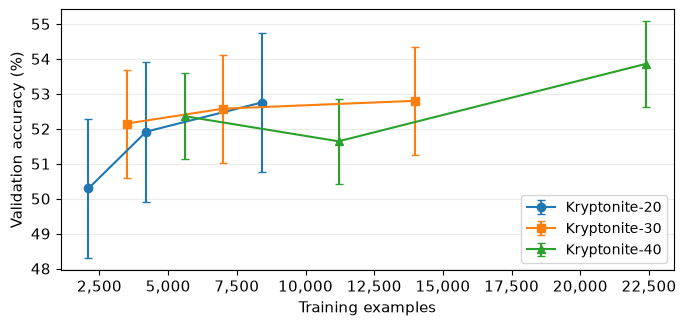

Kryptonite-20, 25% to 100%: +2.46 percentage points
Kryptonite-30, 25% to 100%: +0.65 percentage points
Kryptonite-40, 25% to 100%: +1.50 percentage points


In [3]:
with plt.rc_context({"font.size": 11, "axes.labelsize": 11, "legend.fontsize": 10}):
    fig, ax = plt.subplots(figsize=(6.75, 3.15), layout="constrained")
    for dataset, marker in zip(DATASETS, ("o", "s", "^")):
        sizes = [int(runs[dataset, "quadratic-logistic", p]["training_size"]) for p in PERCENTAGES]
        accuracies = [100 * validation_accuracy(dataset, "quadratic-logistic", p) for p in PERCENTAGES]
        intervals = [accuracy_interval(dataset, "quadratic-logistic", p) for p in PERCENTAGES]
        below = [acc - 100 * ci.low for acc, ci in zip(accuracies, intervals)]
        above = [100 * ci.high - acc for acc, ci in zip(accuracies, intervals)]
        ax.errorbar(sizes, accuracies, yerr=[below, above], marker=marker, capsize=3,
                    label=f"Kryptonite-{dataset}")
    ax.set(xlabel="Training examples", ylabel="Validation accuracy (%)")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    plt.show()

for dataset in DATASETS:
    start = validation_accuracy(dataset, "quadratic-logistic", 25)
    end = validation_accuracy(dataset, "quadratic-logistic", 100)
    print(f"Kryptonite-{dataset}, 25% to 100%: {100 * (end - start):+.2f} percentage points")